# Kịch bản 1:
- 2 biến $X_1$ và $X_2$ độc lập, tuân theo phân phối chuấn $\sim N(0; \sigma^2)$ với $\sigma=1$
- $m(X)$ là hàm tuyến tính của 2 confounding $X_1$ và $X_2$ ảnh hưởng lên $Y$
- $e(X)$ là hàm tuyến tính logistic giữa 2 biến $X_1$ và $X_2$
- $A$ là biến nhị phân tuân theo phân phối Bernoulli với xác suất nhận treatment là e(X)
- $Y$ quan sát được thông qua hàm $m(X) + A \times \tau(X) + \epsilon$ với $\epsilon \sim N(0, \sigma^2)$ với $\sigma=1$
- $\tau(X)$ là mức độ ảnh hưởng của $A$ lên $Y$ (treatment effect) - với $\tau(X) = \tau_0$ (ảnh hưởng của các đối tượng được nhận treatment là đồng nhất)

Vậy, dữ liệu ta quan sát được có các cột: $X_1$ và $X_2$, $A$, $Y$ và các giá trị không quan sát được là $e(X)$, $m(X)$ và $\tau(X)$. 

Ta cần ước lượng $\tau(X)$ bằng Monte Carlo để xác định CI 95%, SE và bias (độ chệch).

Gỉa định: Unconfoundedness đúng, overlap tốt, SUTVA 

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from typing import Tuple

In [23]:
# bộ tham số 
TAU = 3.0
X_COLS = ["X1", "X2"]
TREATMENT = "A"
OUTCOME = "Y"
PS = "ps_true"
ALPHA = 0.0
GAMMA = [0.0, 0.5, 0.5]
BETA = [1.0, 0.5, 0.5]
METHODS = ["Naive", "OLS", "IPTW", "AIPW"]
# plot
BLUE, ORANGE, GRAY = "#6495ed", "#ff7f50", "#8a8984"

## Hàm sinh dữ liệu mô phỏng

Hàm simulate_data() sinh dữ liệu mô phỏng theo kịch bản, có thể thay đổi alpha với $X_2 = \alpha \times X_1$ để thay đổi mức độ overlap/ cộng tuyến giữa 2 biến.

In [3]:
def sigmoid(z:float) -> float:
    "Tính hàm sigmoid"
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

In [4]:
def simulate_data(n:int, seed:int=None, tau:float=TAU, alpha:float=ALPHA, 
                  gamma:Tuple[float]=GAMMA, beta:Tuple[float]=BETA) -> pd.DataFrame:
    """ 
    Sinh dữ liệu mô phỏng: X, A và Y theo kịch bản baseline. Trả về DataFrame.
    :param n: số lượng mẫu quan sát
    :param seed: tái lập 
    :param tau: treatment effect cần ước lượng
    :param alpha: mức độ overlap, alpha thuộc (0;1), càng gần 1 càng overlap kém
    :return df_observed, df_truth: bảng dữ liệu quan sát và dữ liệu truth
    """
    seeds = np.random.SeedSequence(seed).spawn(4)
    rng_x1, rng_x2, rng_a, rng_eps = [np.random.default_rng(s) for s in seeds]

    # Sinh biến độc lập 
    X1 = rng_x1.normal(0, 1, n)
    X2 = alpha*X1 + rng_x2.normal(0, np.sqrt(1-alpha**2), n)
    X = np.column_stack([X1, X2])
    # Sinh propensity score e(X) với e(X) là hàm sigmoid(z)
    g0, g1, g2 = gamma
    ps_true = sigmoid(g0 + g1 * X1 + g2 * X2)
    A = rng_a.binomial(1, ps_true)
    # Baseline outcome 
    b0, b1, b2 = beta
    m_x = b0 + b1 * X1 + b2 * X2
    tau_true = np.full(n, tau)
    eps2 = rng_eps.normal(0.0, 1.0, n)
    # Potential outcome
    Y0 = m_x + eps2
    Y1 = m_x + tau_true + eps2
    # Observed outcome
    Y = np.where(A==1, Y1, Y0)

    df_observed = pd.DataFrame(X, columns=X_COLS)
    df_observed[TREATMENT] = A
    df_observed[OUTCOME] = Y
    df_truth = pd.DataFrame({PS: ps_true, "m_x": m_x, "tau_true": tau_true, "Y0": Y0, "Y1": Y1})
    return df_observed, df_truth

## Kiểm tra dữ liệu trước khi ước lượng

n = 1000, tỷ lệ treated = 49.80%
e_true: min = 0.126, max = 0.915
Naive = 3.522  vs  tau = 3.0  ->  bias = +0.522


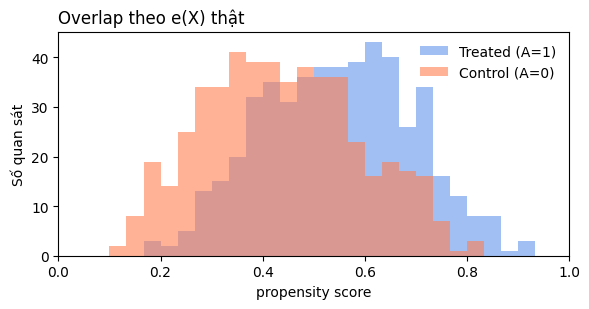

In [13]:
def plot_overlap(ax, e, A, title):
    bins = np.linspace(0, 1, 31)
    ax.hist(e[A == 1], bins=bins, alpha=0.6, color=BLUE, label="Treated (A=1)")
    ax.hist(e[A == 0], bins=bins, alpha=0.6, color=ORANGE, label="Control (A=0)")
    ax.set_title(title, loc="left")
    ax.set_xlabel("propensity score")
    ax.set_xlim(0, 1)

df, truth = simulate_data(1000, seed=2026)
A_arr = df[TREATMENT].to_numpy()

naive = df.loc[df[TREATMENT] == 1, OUTCOME].mean() - df.loc[df[TREATMENT] == 0, OUTCOME].mean()
print(f"n = {len(df)}, tỷ lệ treated = {A_arr.mean():.2%}")
print(f"e_true: min = {truth[PS].min():.3f}, max = {truth[PS].max():.3f}")
print(f"Naive = {naive:.3f}  vs  tau = {TAU}  ->  bias = {naive - TAU:+.3f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
plot_overlap(ax, truth[PS].to_numpy(), A_arr, "Overlap theo e(X) thật")
ax.set_ylabel("Số quan sát")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Uoc lượng propensity score $\widehat{e}(X)$

Logistic regression với đúng các biến X và đúng dạng hàm

In [15]:
def fit_propensity(df:pd.DataFrame):
    # Thêm intercept vào ma trận 
    Xd = sm.add_constant(df[X_COLS].to_numpy()) # [1 X1 X2]
    res = sm.Logit(df[TREATMENT].to_numpy(), Xd).fit()
    return res.predict(Xd), Xd

e_hat, Xd = fit_propensity(df)
print(f"Tương quan e_hat vs e_true: {np.corrcoef(e_hat, truth[PS])[0, 1]:.4f}")
print(f"Sai số tuyệt đối trung bình |e_hat - e_true|: {np.abs(e_hat - truth[PS]).mean():.4f}")

Optimization terminated successfully.
         Current function value: 0.629945
         Iterations 5
Tương quan e_hat vs e_true: 0.9996
Sai số tuyệt đối trung bình |e_hat - e_true|: 0.0144


## Kiểm tra overlap sau ước lượng e(X)

,n,min,max,% e<0.05 hoặc e>0.95
Nhóm,,,,
Treated,498,0.152031,0.935523,0.0
Control,502,0.105483,0.861568,0.0


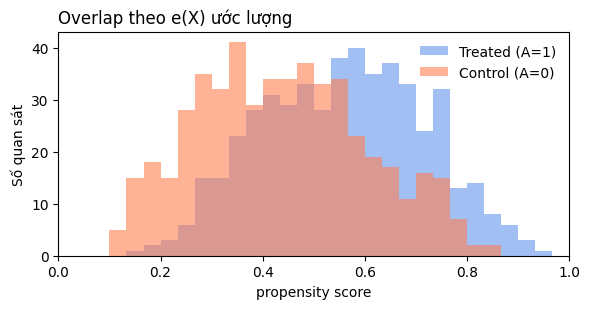

In [16]:
rows = []
for t, name in [(1, "Treated"), (0, "Control")]:
    e_t = e_hat[A_arr == t]
    rows.append({"Nhóm": name, "n": len(e_t), "min": e_t.min(), "max": e_t.max(),
                 "% e<0.05 hoặc e>0.95": np.mean((e_t < 0.05) | (e_t > 0.95)) * 100})
display(pd.DataFrame(rows).set_index("Nhóm"))

fig, ax = plt.subplots(figsize=(6, 3.2))
plot_overlap(ax, e_hat, A_arr, "Overlap theo e(X) ước lượng")
ax.set_ylabel("Số quan sát")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Estimator
1. Naive: So sánh trung bình giữa Y khi A=1 và Y khi A=0
2. OLS: Điều chỉnh X bằng mô hình tuyến tính
3. IPTW: Dùng propensity score để tạo trọng số
4. AIPW: Kết hợp outcome model và propensity score 

In [17]:
def est_naive(Y:Tuple[float], A:Tuple[int]) -> Tuple[float, float]:
    """Tính trung bình giữa 2 nhóm mà chưa điều chỉnh nhiễu"""
    y1, y0 = Y[A == 1], Y[A == 0] # tách y của nhóm Treated và nhóm Control
    ate_hat = y1.mean() - y0.mean()
    se = np.sqrt(y1.var(ddof=1) / len(y1) + y0.var(ddof=1) / len(y0))
    return ate_hat, se   

In [18]:
def est_ols(Y:Tuple[float], A:Tuple[int], X:np.matrix) -> Tuple[float, float]:
    """Dùng Linear Regression để điều chỉnh nhiễu: Y = beta0 + beta1A beta2X1 + beta3X2 + ... + epsilon"""
    X_mat = sm.add_constant(np.column_stack([A, X]))
    # fit mô hình OLS với Robust Standard Errors 
    model = sm.OLS(Y, X_mat).fit(cov_type="HC1")
    ate_hat = model.params[1] 
    se = model.bse[1]
    return ate_hat, se    

In [52]:
def est_iptw(Y: Tuple[float], A:Tuple[int], e:Tuple[float], Xd:np.matrix):
    """IPTW cho ATE, SE có tính đến việc ước lượng e (logit)."""
    n = len(Y) # số lượng mẫu quan sát
    # tính trọng số với 
    # A=1 -> w1 = 1/e; A=0 -> w0 = 1/(1-e)
    w1, w0 = A / e, (1 - A) / (1 - e)
    # Tính ước lượng E[Y(1)] và E[Y(0)] theo quan điểm của Hajek
    mu1 = np.sum(w1 * Y) / np.sum(w1)
    mu0 = np.sum(w0 * Y) / np.sum(w0)

    # influence function bỏ qua việc ước lượng e
    psi = w1 * (Y - mu1) / w1.mean() - w0 * (Y - mu0) / w0.mean()

    # hiệu chỉnh: d(psi)/d(gamma), score và ma trận thông tin của logit
    A1 = ((-w1 * (Y - mu1) * (1 - e))[:, None] * Xd).mean(axis=0) / w1.mean()
    A0 = ((w0 * (Y - mu0) * e)[:, None] * Xd).mean(axis=0) / w0.mean()
    a = A1 - A0
    I = (Xd * (e * (1 - e))[:, None]).T @ Xd / n
    score = (A - e)[:, None] * Xd
    IF = psi + score @ np.linalg.solve(I, a)
    ate_hat = mu1 - mu0
    se = IF.std(ddof=1) / np.sqrt(n)
    return ate_hat, se

In [20]:
def est_aipw(Y: Tuple[float], A:Tuple[int], X:np.matrix, e:Tuple[float]):
    n = len(Y)
    Xc = np.column_stack([np.ones(n), X])
    m = {}
    for t in (0, 1):
        b = np.linalg.lstsq(Xc[A == t], Y[A == t], rcond=None)[0]
        m[t] = Xc @ b
    phi = m[1] - m[0] + A * (Y - m[1]) / e - (1 - A) * (Y - m[0]) / (1 - e)
    ate_hat = phi.mean()
    se = phi.std(ddof=1) / np.sqrt(n)
    return ate_hat, se 

In [21]:
def estimate_all(df):
    """Chạy toàn bộ pipeline ước lượng trên một dataset. Trả về ({method: (est, se)}, e_hat)."""
    Y, A, X = df[OUTCOME].to_numpy(), df[TREATMENT].to_numpy(), df[X_COLS].to_numpy()
    e, Xd = fit_propensity(df)
    out = {
        "Naive": est_naive(Y, A),
        "OLS": est_ols(Y, A, X),
        "IPTW": est_iptw(Y, A, e, Xd),
        "AIPW": est_aipw(Y, A, X, e),
    }
    return out, e

## Check balance

,SMD trước,SMD sau IPTW
X1,0.499867,0.016079
X2,0.478633,0.034656


ESS treated: 439 / 498
ESS control: 430 / 502
Trọng số lớn nhất: 7.22


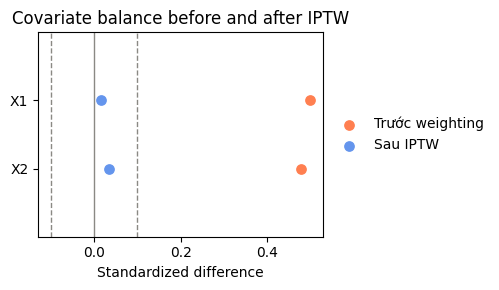

In [50]:
def smd(df, w=None):
    A = df[TREATMENT].to_numpy()
    w = np.ones(len(df)) if w is None else w
    out = {}
    for c in X_COLS:
        x = df[c].to_numpy()
        m1 = np.average(x[A == 1], weights=w[A == 1])
        m0 = np.average(x[A == 0], weights=w[A == 0])
        s = np.sqrt((x[A == 1].var(ddof=1) + x[A == 0].var(ddof=1)) / 2)   # SD gốc, chưa gia quyền
        out[c] = (m1 - m0) / s
    return pd.Series(out)


def ate_weights(A, e):
    return A / e + (1 - A) / (1 - e)


def ess(w):
    return w.sum() ** 2 / (w ** 2).sum()


w = ate_weights(A_arr, e_hat)
bal = pd.DataFrame({"SMD trước": smd(df), "SMD sau IPTW": smd(df, w)})
display(bal)

print(f"ESS treated: {ess(w[A_arr == 1]):.0f} / {int((A_arr == 1).sum())}")
print(f"ESS control: {ess(w[A_arr == 0]):.0f} / {int((A_arr == 0).sum())}")
print(f"Trọng số lớn nhất: {w.max():.2f}")

# Love plot
fig, ax = plt.subplots(figsize=(6, 3))
ypos = [0.4, 0.6]
ax.set_ylim(0.2, 0.8)
ax.axvline(0, color=GRAY, lw=1)
for s in (-0.1, 0.1):
    ax.axvline(s, color=GRAY, lw=1, ls="--")
ax.scatter(bal["SMD trước"], ypos, color=ORANGE, s=45, zorder=3, label="Trước weighting")
ax.scatter(bal["SMD sau IPTW"], ypos, color=BLUE, s=45, zorder=3, label="Sau IPTW")
ax.set_yticks(ypos)
ax.set_yticklabels(bal.index)
ax.invert_yaxis()
ax.set_xlabel("Standardized difference")
ax.set_title("Covariate balance before and after IPTW", loc="center")
ax.grid(axis="y", alpha=0)
ax.legend(title="",frameon=False,loc="center left",bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

## Chạy 1 lần

In [53]:
def bootstrap_se(df, B=200, seed=0):
    rng = np.random.default_rng(seed)
    n = len(df)
    draws = {m: [] for m in METHODS}
    for _ in range(B):
        idx = rng.integers(0, n, n)
        out, _ = estimate_all(df.iloc[idx].reset_index(drop=True))
        for m in METHODS:
            draws[m].append(out[m][0])
    return {m: np.std(v, ddof=1) for m, v in draws.items()}


out, _ = estimate_all(df)
boot = bootstrap_se(df)

rows = []
for m in METHODS:
    est, se = out[m]
    lo, hi = est - 1.96 * se, est + 1.96 * se
    rows.append({"method": m, "estimate": est, "bias (est - tau)": est - TAU,
                 "SE": se, "SE bootstrap": boot[m],
                 "CI95 low": lo, "CI95 high": hi, "CI chứa tau?": lo <= TAU <= hi})
single = pd.DataFrame(rows).set_index("method")
single

Optimization terminated successfully.
         Current function value: 0.629945
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.619911
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.630477
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.618281
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.637856
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.644916
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.629648
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.597059
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.627026
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.630286
  

,estimate,bias (est - tau),SE,SE bootstrap,CI95 low,CI95 high,CI chứa tau?
method,,,,,,,
Naive,3.522482,0.522482,0.076063,0.075222,3.373399,3.671566,False
OLS,3.025728,0.025728,0.068361,0.069450,2.891740,3.159715,True
IPTW,3.044715,0.044715,0.069758,0.070448,2.907989,3.181441,True
AIPW,3.018953,0.018953,0.068372,0.070685,2.884943,3.152962,True


## Monte Carlo

In [58]:
def one_rep(n, **kw):
    d, _ = simulate_data(n, **kw)
    out, e = estimate_all(d)
    T = d[TREATMENT].to_numpy()
    extras = {"max_abs_smd_after": smd(d, ate_weights(T, e)).abs().max(),
              "max_abs_smd_before": smd(d).abs().max(),
              "e_min": e.min(), "e_max": e.max(),
              "max_w": ate_weights(T, e).max()}
    return out, extras


def run_mc(R, n, seed=123, **kw):
    children = np.random.SeedSequence(seed).spawn(R)
    recs, extras = [], []
    for ss in children:
        out, ex = one_rep(n, **kw)
        recs.append(out)
        extras.append(ex)
    return recs, pd.DataFrame(extras)


def summarize_mc(recs, tau=TAU):
    rows = []
    for m in METHODS:
        est = np.array([r[m][0] for r in recs])
        se = np.array([r[m][1] for r in recs])
        sd = est.std(ddof=1)
        rows.append({
            "method": m,
            "bias": est.mean() - tau,
            "MC SE(bias)": sd / np.sqrt(len(est)),
            "emp. SD": sd,
            "RMSE": np.sqrt(np.mean((est - tau) ** 2)),
            "mean SE": se.mean(),
            "SE/SD": se.mean() / sd,
            "coverage": np.mean((est - 1.96 * se <= tau) & (tau <= est + 1.96 * se)),
        })
    return pd.DataFrame(rows).set_index("method")


R, N = 1000, 1000
recs, extras = run_mc(R, N)
res = summarize_mc(recs)
res

Optimization terminated successfully.
         Current function value: 0.648583
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.633884
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.642704
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.657449
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.625900
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.640680
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.624473
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.651123
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.634132
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.640508
  

,bias,MC SE(bias),emp. SD,RMSE,mean SE,SE/SD,coverage
method,,,,,,,
Naive,0.449335,0.002409,0.076195,0.455744,0.076173,0.999719,0.000
OLS,0.000492,0.002059,0.065114,0.065084,0.066713,1.024550,0.956
IPTW,0.000893,0.002127,0.067258,0.067230,0.068816,1.023163,0.960
AIPW,0.000415,0.002073,0.065551,0.065519,0.067452,1.029004,0.962


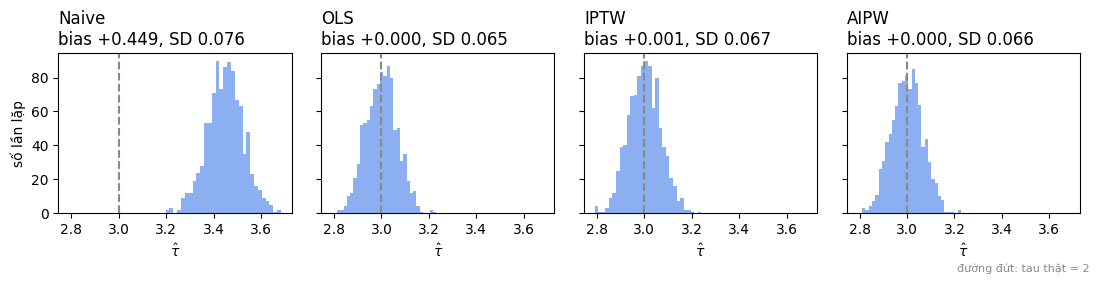

In [59]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharex=True, sharey=True)
for ax, m in zip(axes, METHODS):
    est = np.array([r[m][0] for r in recs])
    ax.hist(est, bins=30, color=BLUE, alpha=0.75)
    ax.axvline(TAU, color=GRAY, lw=1.5, ls="--")
    ax.set_title(f"{m}\nbias {res.loc[m, 'bias']:+.3f}, SD {res.loc[m, 'emp. SD']:.3f}", loc="left")
    ax.set_xlabel(r"$\hat\tau$")
axes[0].set_ylabel("số lần lặp")
fig.text(0.995, 0.01, "đường đứt: tau thật = 2", ha="right", fontsize=8, color=GRAY)
plt.tight_layout()
plt.show()

## Kiểm tra mức độ hội tụ khi thay đổi cỡ mẫu

In [60]:
rows = []
for n in [500, 1000, 5000]:
    r_n, _ = run_mc(300, n, seed=7)
    s = summarize_mc(r_n)
    for m in ["OLS", "IPTW", "AIPW"]:
        rows.append({"n": n, "method": m, "bias": s.loc[m, "bias"],
                     "RMSE": s.loc[m, "RMSE"],
                     "RMSE x sqrt(n)": s.loc[m, "RMSE"] * np.sqrt(n),
                     "coverage": s.loc[m, "coverage"]})
sweep = pd.DataFrame(rows).set_index(["method", "n"]).sort_index().round(4)
sweep

Optimization terminated successfully.
         Current function value: 0.657150
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.630004
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.643404
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.657175
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.647227
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.635629
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.650724
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.626298
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.626262
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.613611
  

bias    RMSE  RMSE x sqrt(n)  coverage
method n                                             
AIPW   500   0.0080  0.0958          2.1412    0.9467
       1000 -0.0043  0.0730          2.3097    0.9300
       5000 -0.0006  0.0278          1.9675    0.9667
IPTW   500   0.0092  0.0980          2.1923    0.9433
       1000 -0.0032  0.0737          2.3307    0.9300
       5000 -0.0006  0.0279          1.9724    0.9700
OLS    500   0.0089  0.0955          2.1364    0.9467
       1000 -0.0033  0.0719          2.2722    0.9333
       5000 -0.0006  0.0276          1.9510    0.9633